# Proyek Analisis Data: [E-Commerce Public Dataset]
- **Nama:** Rudi Gunawan
- **Email:** rudigunawan4571@gmail.com
- **ID Dicoding:** koharu_liddel

## Menentukan Pertanyaan Bisnis

**SMART Question** adalah sebuah framework untuk merumuskan pertanyaan secara terstruktur agar memeperoleh informasi yang mendalam.

* **Spesific (Spesifik)**
  * Pertanyaan harus jelas, fokus pada sebuah topik tertentu, dan tidak bermakna ganda. Hindari pertanyaan yang terlalu luas.
    * Salah: Bagaimana cara meningkatkan penjualan?
    * Benar: Faktor apa saja yang memengaruhi penurunan penjualan produk kategori elektronik di wilayah Jakarta selama kuartal terakhir?
* **Measurable (Terukur)**
  * Pertanyaan harus bisa dijawab dengan angka atau matrix yang konkret, harus tahu apa yang akan dihitung.
    * Salah: Apakah pelanggan senang dengan layanan kita?
    * Benar: Berapa skor rata-rata Customer Satisfaction untuk layanan purna jual bulan ini dibandingkan bulan lalu?
* **Action-Oriented (Berorientasi Aksi)**
  * Hasil dari pertanyaan harus bisa memberikan arahan untuk melakukan tindakan nyata. Jika pertanyaan terjawab, stakeholder harus tahu apa langkah selanjutnya.
    * Salah: Mengapa orang suka berbelanja?
    * Benar: Fitur apa pada aplikasi yang paling sering digunakan sebelum pengguna memutuskan untuk melakukan checkout?
* **Relevant (Relevan)**
  * Hasil dari pertanyaan harus sejalan dengan tujuan utama bisnis atau masalah yang sedang dihadapi.
    * Salah: Menanyakan tentang stok gudang saat masalah utamanya adalah efektivitas kampanye media sosial.
    * Benar: Apakah kampanye iklan di Instagram memberikan Return on Ad Spend (ROAS) yang lebih tinggi dibandingkan iklan di TikTok?
* **Time-bound (Terikat Waktu)**
  * Pertanyaan harus ada batasan waktu yang jelas agar analisis memiliki konteks yang tepat.
    * Salah: Berapa banyak pengguna baru kita?
    * Benar: Berapa tingkat pertumbuhan pengguna baru secara bulanan (Month-over-Month) sepanjang tahun 2025?

**Contoh pertanyaan bisnis yang memenuhi seluruh elemen SMART**

***"Faktor apa saja yang memengaruhi penurunan conversion rate pada pengguna aplikasi Android di wilayah Jabodetabek sebesar 5% selama periode Flash Sale Maret 2026?"***

Keterangan:

- **Specific**: Fokus pada "penurunan conversion rate" untuk "aplikasi Android" di "Jabodetabek". Bukan sekadar penjualan turun.
- **Measurable**: Ada angka konkret yang ingin dianalisis, yaitu penurunan sebesar "5%".
- **Action-Oriented**: Dengan mengetahui faktor penyebabnya misalnya bug pada versi Android tertentu atau kendala logistik di Jabodetabek, tim bisa langsung melakukan perbaikan teknis atau operasional.
- **Relevant**: Penurunan konversi saat Flash Sale adalah masalah kritis bagi bisnis retail/e-commerce.
- **Time-bound**: Dibatasi pada periode spesifik "Flash Sale Maret 2026".

- **Pertanyaan 1:** Metode pembayaran apa yang paling banyak digunakan pelanggan sepanjang 1 Januari 2017 hingga 17 Oktober 2018, dan apakah ada tren pergeseran preferensi metode pembayaran dari tahun ke tahun?
- **Pertanyaan 2:** Kategori produk apa yang paling laris dibeli pelanggan selama 1 Januari hingga 3 September 2018, dan kategori apa yang berpotensi untuk ditambah stok/promosinya?

## Import Semua Packages/Library yang Digunakan

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sn

## Data Wrangling

### Gathering Data

#### Load df E-Commerce Public Dataset

In [2]:
#Load the raw datasets
orders_df = pd.read_csv('data/E-Commerce Public Dataset/orders_dataset.csv')
order_payments_df = pd.read_csv('data/E-Commerce Public Dataset/order_payments_dataset.csv')
order_items_df = pd.read_csv('data/E-Commerce Public Dataset/order_items_dataset.csv')
products_df = pd.read_csv('data/E-Commerce Public Dataset/products_dataset.csv')
product_category_translation_df = pd.read_csv('data/E-Commerce Public Dataset/product_category_name_translation.csv')

#### Menggabungkan Data untuk Analisis

Karena data pembayaran dan kategori produk tersebar di beberapa tabel berbeda, 
tabel-tabel berikut digabungkan untuk menjawab masing-masing pertanyaan bisnis:
- metode_pembayaran: orders + order_payments
- kategori_produk: orders + order_items + products + category_translation

In [3]:
# Metode pembayaran

payment_df = orders_df.merge(order_payments_df, on='order_id', how='left')


# Kategori produk

category_df = orders_df.merge(order_items_df, on='order_id', how='left')
category_df = category_df.merge(products_df, on='product_id', how='left')
category_df = category_df.merge(product_category_translation_df, on='product_category_name', how='left')

payment_df.to_csv('data/metode_pembayaran.csv', index=False)
category_df.to_csv('data/kategori_produk.csv', index=False)

#### load dataset yang telah digabungkan
setelah data pembayaran dan kategori produk yang tersebar digabungkan, 
dataset tersebut akan digunakan untuk analisis dan menjawab pertanyaan bisnis.

In [4]:
metode_df = pd.read_csv('data/metode_pembayaran.csv')

metode_df.head(5)

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,payment_sequential,payment_type,payment_installments,payment_value
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18 00:00:00,1.0,credit_card,1.0,18.12
1,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18 00:00:00,3.0,voucher,1.0,2.00
2,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18 00:00:00,2.0,voucher,1.0,18.59
3,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13 00:00:00,1.0,boleto,1.0,141.46
4,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04 00:00:00,1.0,credit_card,3.0,179.12


In [5]:
kategori_df = pd.read_csv('data/kategori_produk.csv')

kategori_df.head(5)

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,order_item_id,product_id,...,freight_value,product_category_name,product_name_lenght,product_description_lenght,product_photos_qty,product_weight_g,product_length_cm,product_height_cm,product_width_cm,product_category_name_english
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18 00:00:00,1.0,87285b34884572647811a353c7ac498a,...,8.72,utilidades_domesticas,40.0,268.0,4.0,500.0,19.0,8.0,13.0,housewares
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13 00:00:00,1.0,595fac2a385ac33a80bd5114aec74eb8,...,22.76,perfumaria,29.0,178.0,1.0,400.0,19.0,13.0,19.0,perfumery
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04 00:00:00,1.0,aa4383b373c6aca5d8797843e5594415,...,19.22,automotivo,46.0,232.0,1.0,420.0,24.0,19.0,21.0,auto
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15 00:00:00,1.0,d0b61bfb1de832b15ba9d266ca96e5b0,...,27.20,pet_shop,59.0,468.0,3.0,450.0,30.0,10.0,20.0,pet_shop
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26 00:00:00,1.0,65266b2da20d04dbe00c5c2d3bb7859e,...,8.72,papelaria,38.0,316.0,4.0,250.0,51.0,15.0,15.0,stationery


**Insight:**
- `metode_df` merupakan hasil penggabungan data pesanan (orders) dengan data pembayaran 
  (order_payments), terdiri dari 12 kolom termasuk informasi waktu pemesanan dan metode 
  pembayaran yang digunakan. Terlihat ada beberapa baris dengan `order_id` yang sama 
  (contoh: 3 baris pertama), menandakan satu pesanan bisa memiliki lebih dari satu 
  metode pembayaran (misal kombinasi voucher + kartu kredit).
- `kategori_df` merupakan hasil penggabungan data pesanan dengan detail item, produk, 
  dan terjemahan nama kategori produk, yang akan digunakan untuk mengidentifikasi 
  kategori produk apa saja yang paling banyak dibeli pelanggan.

### Assessing Data

#### Identifying `metode_df` problem

##### Menilai tabel `metode_df`

In [6]:
metode_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 103887 entries, 0 to 103886
Data columns (total 12 columns):
 #   Column                         Non-Null Count   Dtype  
---  ------                         --------------   -----  
 0   order_id                       103887 non-null  object 
 1   customer_id                    103887 non-null  object 
 2   order_status                   103887 non-null  object 
 3   order_purchase_timestamp       103887 non-null  object 
 4   order_approved_at              103712 non-null  object 
 5   order_delivered_carrier_date   101999 non-null  object 
 6   order_delivered_customer_date  100755 non-null  object 
 7   order_estimated_delivery_date  103887 non-null  object 
 8   payment_sequential             103886 non-null  float64
 9   payment_type                   103886 non-null  object 
 10  payment_installments           103886 non-null  float64
 11  payment_value                  103886 non-null  float64
dtypes: float64(3), object(9)
memor

In [7]:
metode_df.isna().sum()

order_id                            0
customer_id                         0
order_status                        0
order_purchase_timestamp            0
order_approved_at                 175
order_delivered_carrier_date     1888
order_delivered_customer_date    3132
order_estimated_delivery_date       0
payment_sequential                  1
payment_type                        1
payment_installments                1
payment_value                       1
dtype: int64

In [8]:
print("Jumlah duplikasi: ", metode_df.duplicated().sum())

Jumlah duplikasi:  0


In [9]:
metode_df.describe()

,payment_sequential,payment_installments,payment_value
count,103886.000000,103886.000000,103886.000000
mean,1.092679,2.853349,154.100380
std,0.706584,2.687051,217.494064
min,1.000000,0.000000,0.000000
25%,1.000000,1.000000,56.790000
50%,1.000000,1.000000,100.000000
75%,1.000000,4.000000,171.837500
max,29.000000,24.000000,13664.080000


**Steps to Take:**
- Mengisi atau membiarkan missing value pada kolom tanggal pengiriman karena 
  berkaitan dengan status pesanan yang belum selesai (bukan error data), 
  cukup didokumentasikan tanpa dihapus barisnya.
- Menghapus 1 baris dengan missing value pada kolom `payment_type` dan sejenisnya 
  karena jumlahnya sangat kecil (hanya 1 baris) dan tidak signifikan terhadap data.
- Memeriksa 9 baris dengan `payment_value = 0`. Setelah ditelusuri,
  nilai tersebut merupakan bagian dari transaksi dengan pembayaran
  majemuk (split payment dalam satu order_id), sehingga tetap
  dipertahankan dan tidak dianggap sebagai kesalahan data. Untuk
  payment_installments = 0, nilai diperbaiki menjadi 1 karena
  mengindikasikan anomali pencatatan.
- Mempertahankan outlier pada `payment_value` karena kemungkinan merupakan 
  transaksi sah (pembelian dalam jumlah besar), namun tetap dicatat sebagai 
  catatan analisis.

**Insight:** (Opsional)
- Dataset `metode_df` memiliki 103.887 baris dan 12 kolom, dengan beberapa kolom 
  tanggal pengiriman (`order_approved_at`, `order_delivered_carrier_date`, 
  `order_delivered_customer_date`) mengandung missing value, kemungkinan karena 
  pesanan belum sampai tahap tersebut (misal masih berstatus "processing" atau 
  "canceled").
- Tidak ditemukan baris duplikat secara keseluruhan (0 baris), namun `order_id` 
  ada yang muncul berulang karena satu pesanan dapat menggunakan lebih dari satu 
  metode pembayaran (misalnya kombinasi voucher dan kartu kredit).
- Ditemukan outlier pada kolom `payment_value`, dengan nilai maksimum mencapai 
  13.664 sementara rata-ratanya hanya 154 — menandakan adanya transaksi bernilai 
  sangat besar dibanding mayoritas data.
- Ditemukan 9 baris dengan `payment_value = 0` dan 2 baris dengan 
  `payment_installments = 0`, yang secara logis bisnis tidak wajar untuk 
  sebuah transaksi pembayaran.

#### Identifying `metode_df` problem

##### Menilai tabel `kategori_df`

In [10]:
kategori_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 113425 entries, 0 to 113424
Data columns (total 23 columns):
 #   Column                         Non-Null Count   Dtype  
---  ------                         --------------   -----  
 0   order_id                       113425 non-null  object 
 1   customer_id                    113425 non-null  object 
 2   order_status                   113425 non-null  object 
 3   order_purchase_timestamp       113425 non-null  object 
 4   order_approved_at              113264 non-null  object 
 5   order_delivered_carrier_date   111457 non-null  object 
 6   order_delivered_customer_date  110196 non-null  object 
 7   order_estimated_delivery_date  113425 non-null  object 
 8   order_item_id                  112650 non-null  float64
 9   product_id                     112650 non-null  object 
 10  seller_id                      112650 non-null  object 
 11  shipping_limit_date            112650 non-null  object 
 12  price                         

In [11]:
kategori_df.isna().sum()

order_id                            0
customer_id                         0
order_status                        0
order_purchase_timestamp            0
order_approved_at                 161
order_delivered_carrier_date     1968
order_delivered_customer_date    3229
order_estimated_delivery_date       0
order_item_id                     775
product_id                        775
seller_id                         775
shipping_limit_date               775
price                             775
freight_value                     775
product_category_name            2378
product_name_lenght              2378
product_description_lenght       2378
product_photos_qty               2378
product_weight_g                  793
product_length_cm                 793
product_height_cm                 793
product_width_cm                  793
product_category_name_english    2402
dtype: int64

In [12]:
print("Jumlah duplikasi: ", kategori_df.duplicated().sum())

Jumlah duplikasi:  0


In [13]:
kategori_df.describe()

,order_item_id,price,freight_value,product_name_lenght,product_description_lenght,product_photos_qty,product_weight_g,product_length_cm,product_height_cm,product_width_cm
count,112650.000000,112650.000000,112650.000000,111047.000000,111047.000000,111047.000000,112632.000000,112632.000000,112632.000000,112632.000000
mean,1.197834,120.653739,19.990320,48.775978,787.867029,2.209713,2093.672047,30.153669,16.593766,22.996546
std,0.705124,183.633928,15.806405,10.025581,652.135608,1.721438,3751.596884,16.153449,13.443483,11.707268
min,1.000000,0.850000,0.000000,5.000000,4.000000,1.000000,0.000000,7.000000,2.000000,6.000000
25%,1.000000,39.900000,13.080000,42.000000,348.000000,1.000000,300.000000,18.000000,8.000000,15.000000
50%,1.000000,74.990000,16.260000,52.000000,603.000000,1.000000,700.000000,25.000000,13.000000,20.000000
75%,1.000000,134.900000,21.150000,57.000000,987.000000,3.000000,1800.000000,38.000000,20.000000,30.000000
max,21.000000,6735.000000,409.680000,76.000000,3992.000000,20.000000,40425.000000,105.000000,105.000000,118.000000


**Steps to Take:**
- Menghapus baris yang memiliki missing value pada
 `product_category_name_english` menggunakan kolom tersebut sebagai
  dasar penghapusan, karena kategori produk diperlukan untuk
  menjawab pertanyaan bisnis. Proses ini menghapus 2.402 baris.
- Missing value pada kolom dimensi produk seperti
  `product_weight_g`, `product_length_cm`, `product_height_cm`, dan
  `product_width_cm` tidak dihapus karena tidak digunakan dalam
  analisis utama. Setelah penghapusan baris berdasarkan
  product_category_name_english, hanya tersisa 1 baris dengan
  missing value pada kolom dimensi tersebut.
- Menggunakan kolom `product_category_name_english` sebagai acuan nama 
  kategori pada seluruh proses analisis dan visualisasi selanjutnya.
- Mempertahankan outlier pada `price` karena termasuk variasi harga produk 
  yang wajar (produk elektronik/furnitur cenderung lebih mahal dibanding 
  aksesoris kecil).

**Insight:** (Opsional)
- Dataset `kategori_df` memiliki 113.425 baris dan 23 kolom, dengan missing 
  value terbanyak pada kolom terkait kategori produk (`product_category_name`, 
  `product_category_name_english`) sebanyak lebih dari 2.300 baris, serta 
  kolom harga dan detail produk (`price`, `freight_value`, `product_id`, dll) 
  sebanyak 775 baris.
- Tidak ditemukan baris duplikat secara keseluruhan, namun `order_id` muncul 
  berulang karena satu pesanan dapat berisi lebih dari satu item produk.
- Ditemukan outlier pada kolom `price`, dengan nilai maksimum mencapai 6.735 
  sementara rata-ratanya hanya sekitar 120, serta `freight_value` dengan 
  maksimum 409 dibanding rata-rata 20.
- Nama kategori produk (`product_category_name`) masih dalam Bahasa Portugis, 
  sehingga perlu digunakan kolom terjemahan (`product_category_name_english`) 
  agar lebih mudah dipahami saat visualisasi.

### Cleaning Data

#### Fixing `metode_df` problem

#### Membersihkan tabel `metode_df`

##### Duplicate data

In [14]:
print("Jumlah duplikasi: ", metode_df.duplicated().sum())

Jumlah duplikasi:  0


##### Missing values

In [15]:
metode_df.isna().sum()

order_id                            0
customer_id                         0
order_status                        0
order_purchase_timestamp            0
order_approved_at                 175
order_delivered_carrier_date     1888
order_delivered_customer_date    3132
order_estimated_delivery_date       0
payment_sequential                  1
payment_type                        1
payment_installments                1
payment_value                       1
dtype: int64

In [16]:
metode_df[metode_df.order_approved_at.isna()]

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,payment_sequential,payment_type,payment_installments,payment_value
1175,00b1cb0320190ca0daa2c88b35206009,3532ba38a3fd242259a514ac2b6ae6b6,canceled,2018-08-28 15:26:39,NaN,NaN,NaN,2018-09-12 00:00:00,1.0,not_defined,1.0,0.00
1876,ed3efbd3a87bea76c2812c66a0b32219,191984a8ba4cbb2145acb4fe35b69664,canceled,2018-09-20 13:54:16,NaN,NaN,NaN,2018-10-17 00:00:00,1.0,voucher,1.0,191.46
1948,df8282afe61008dc26c6c31011474d02,aa797b187b5466bc6925aaaa4bb3bed1,canceled,2017-03-04 12:14:30,NaN,NaN,NaN,2017-04-10 00:00:00,1.0,boleto,1.0,139.96
2115,8d4c637f1accf7a88a4555f02741e606,b1dd715db389a2077f43174e7a675d07,canceled,2018-08-29 16:27:49,NaN,NaN,NaN,2018-09-13 00:00:00,1.0,voucher,1.0,66.44
2255,7a9d4c7f9b068337875b95465330f2fc,7f71ae48074c0cfec9195f88fcbfac55,canceled,2017-05-01 16:12:39,NaN,NaN,NaN,2017-05-30 00:00:00,1.0,credit_card,2.0,72.90
...,...,...,...,...,...,...,...,...,...,...,...,...
102047,5a00b4d35edffc56b825c3646a99ba9d,6a3bdf004ca96338fb5fad1b8d93c2e6,canceled,2017-07-02 15:38:46,NaN,NaN,NaN,2017-07-25 00:00:00,1.0,credit_card,1.0,157.13
102812,227c804e2a44760671a6a5697ea549e4,62e7477e75e542243ee62a0ba73f410f,canceled,2017-09-28 15:02:56,NaN,NaN,NaN,2017-10-16 00:00:00,1.0,credit_card,1.0,280.20
103329,e49e7ce1471b4693482d40c2bd3ad196,e4e7ab3f449aeb401f0216f86c2104db,canceled,2018-08-07 11:16:28,NaN,NaN,NaN,2018-08-10 00:00:00,1.0,voucher,1.0,54.42
103723,3a3cddda5a7c27851bd96c3313412840,0b0d6095c5555fe083844281f6b093bb,canceled,2018-08-31 16:13:44,NaN,NaN,NaN,2018-10-01 00:00:00,1.0,voucher,1.0,63.89


In [17]:
metode_df[metode_df.order_delivered_carrier_date.isna()]

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,payment_sequential,payment_type,payment_installments,payment_value
8,136cce7faa42fdb2cefd53fdc79a6098,ed0271e0b7da060a393796590e7b737a,invoiced,2017-04-11 12:22:08,2017-04-13 13:25:17,NaN,NaN,2017-05-09 00:00:00,1.0,credit_card,1.0,65.95
110,0760a852e4e9d89eb77bf631eaaf1c84,d2a79636084590b7465af8ab374a8cf5,invoiced,2018-08-03 17:44:42,2018-08-07 06:15:14,NaN,NaN,2018-08-21 00:00:00,1.0,boleto,1.0,50.35
135,15bed8e2fec7fdbadb186b57c46c92f2,f3f0e613e0bdb9c7cee75504f0f90679,processing,2017-09-03 14:22:03,2017-09-03 14:30:09,NaN,NaN,2017-10-03 00:00:00,1.0,credit_card,2.0,138.28
279,8e24261a7e58791d10cb1bf9da94df5c,64a254d30eed42cd0e6c36dddb88adf0,unavailable,2017-11-16 15:09:28,2017-11-16 15:26:57,NaN,NaN,2017-12-05 00:00:00,1.0,credit_card,5.0,84.00
340,d3c8851a6651eeff2f73b0e011ac45d0,957f8e082185574de25992dc659ebbc0,processing,2016-10-05 22:44:13,2016-10-06 15:51:05,NaN,NaN,2016-12-09 00:00:00,1.0,credit_card,1.0,299.84
...,...,...,...,...,...,...,...,...,...,...,...,...
103723,3a3cddda5a7c27851bd96c3313412840,0b0d6095c5555fe083844281f6b093bb,canceled,2018-08-31 16:13:44,NaN,NaN,NaN,2018-10-01 00:00:00,1.0,voucher,1.0,63.89
103754,e9e64a17afa9653aacf2616d94c005b8,b4cd0522e632e481f8eaf766a2646e86,processing,2018-01-05 23:07:24,2018-01-09 07:18:05,NaN,NaN,2018-02-06 00:00:00,1.0,boleto,1.0,144.56
103791,a89abace0dcc01eeb267a9660b5ac126,2f0524a7b1b3845a1a57fcf3910c4333,canceled,2018-09-06 18:45:47,NaN,NaN,NaN,2018-09-27 00:00:00,1.0,voucher,1.0,107.13
103792,a69ba794cc7deb415c3e15a0a3877e69,726f0894b5becdf952ea537d5266e543,unavailable,2017-08-23 16:28:04,2017-08-28 15:44:47,NaN,NaN,2017-09-15 00:00:00,1.0,credit_card,2.0,195.91


In [18]:
metode_df[metode_df.order_delivered_customer_date.isna()]

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,payment_sequential,payment_type,payment_installments,payment_value
8,136cce7faa42fdb2cefd53fdc79a6098,ed0271e0b7da060a393796590e7b737a,invoiced,2017-04-11 12:22:08,2017-04-13 13:25:17,NaN,NaN,2017-05-09 00:00:00,1.0,credit_card,1.0,65.95
49,ee64d42b8cf066f35eac1cf57de1aa85,caded193e8e47b8362864762a83db3c5,shipped,2018-06-04 16:44:48,2018-06-05 04:31:18,2018-06-05 14:32:00,NaN,2018-06-28 00:00:00,1.0,boleto,1.0,22.36
110,0760a852e4e9d89eb77bf631eaaf1c84,d2a79636084590b7465af8ab374a8cf5,invoiced,2018-08-03 17:44:42,2018-08-07 06:15:14,NaN,NaN,2018-08-21 00:00:00,1.0,boleto,1.0,50.35
135,15bed8e2fec7fdbadb186b57c46c92f2,f3f0e613e0bdb9c7cee75504f0f90679,processing,2017-09-03 14:22:03,2017-09-03 14:30:09,NaN,NaN,2017-10-03 00:00:00,1.0,credit_card,2.0,138.28
161,6942b8da583c2f9957e990d028607019,52006a9383bf149a4fb24226b173106f,shipped,2018-01-10 11:33:07,2018-01-11 02:32:30,2018-01-11 19:39:23,NaN,2018-02-07 00:00:00,1.0,boleto,1.0,69.12
...,...,...,...,...,...,...,...,...,...,...,...,...
103723,3a3cddda5a7c27851bd96c3313412840,0b0d6095c5555fe083844281f6b093bb,canceled,2018-08-31 16:13:44,NaN,NaN,NaN,2018-10-01 00:00:00,1.0,voucher,1.0,63.89
103754,e9e64a17afa9653aacf2616d94c005b8,b4cd0522e632e481f8eaf766a2646e86,processing,2018-01-05 23:07:24,2018-01-09 07:18:05,NaN,NaN,2018-02-06 00:00:00,1.0,boleto,1.0,144.56
103791,a89abace0dcc01eeb267a9660b5ac126,2f0524a7b1b3845a1a57fcf3910c4333,canceled,2018-09-06 18:45:47,NaN,NaN,NaN,2018-09-27 00:00:00,1.0,voucher,1.0,107.13
103792,a69ba794cc7deb415c3e15a0a3877e69,726f0894b5becdf952ea537d5266e543,unavailable,2017-08-23 16:28:04,2017-08-28 15:44:47,NaN,NaN,2017-09-15 00:00:00,1.0,credit_card,2.0,195.91


In [19]:
metode_df[metode_df.payment_sequential.isna()]

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,payment_sequential,payment_type,payment_installments,payment_value
32133,bfbd0f9bdef84302105ad712db648a6c,86dc2ffce2dfff336de2f386a786e574,delivered,2016-09-15 12:16:38,2016-09-15 12:16:38,2016-11-07 17:11:53,2016-11-09 07:47:38,2016-10-04 00:00:00,NaN,NaN,NaN,NaN


In [20]:
metode_df[metode_df.payment_type.isna()]

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,payment_sequential,payment_type,payment_installments,payment_value
32133,bfbd0f9bdef84302105ad712db648a6c,86dc2ffce2dfff336de2f386a786e574,delivered,2016-09-15 12:16:38,2016-09-15 12:16:38,2016-11-07 17:11:53,2016-11-09 07:47:38,2016-10-04 00:00:00,NaN,NaN,NaN,NaN


In [21]:
metode_df[metode_df.payment_installments.isna()]

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,payment_sequential,payment_type,payment_installments,payment_value
32133,bfbd0f9bdef84302105ad712db648a6c,86dc2ffce2dfff336de2f386a786e574,delivered,2016-09-15 12:16:38,2016-09-15 12:16:38,2016-11-07 17:11:53,2016-11-09 07:47:38,2016-10-04 00:00:00,NaN,NaN,NaN,NaN


In [22]:
metode_df[metode_df.payment_value.isna()]

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,payment_sequential,payment_type,payment_installments,payment_value
32133,bfbd0f9bdef84302105ad712db648a6c,86dc2ffce2dfff336de2f386a786e574,delivered,2016-09-15 12:16:38,2016-09-15 12:16:38,2016-11-07 17:11:53,2016-11-09 07:47:38,2016-10-04 00:00:00,NaN,NaN,NaN,NaN


In [23]:
metode_df.dropna(subset=['payment_type'], inplace=True)

In [24]:
metode_df.isna().sum()

order_id                            0
customer_id                         0
order_status                        0
order_purchase_timestamp            0
order_approved_at                 175
order_delivered_carrier_date     1888
order_delivered_customer_date    3132
order_estimated_delivery_date       0
payment_sequential                  0
payment_type                        0
payment_installments                0
payment_value                       0
dtype: int64

**Catatan**
- Missing value pada kolom `order_approved_at`, `order_delivered_carrier_date`, 
  dan `order_delivered_customer_date` ternyata berkaitan erat dengan 
  `order_status` pesanan. Hasil pengecekan menunjukkan bahwa mayoritas baris 
  dengan `order_delivered_customer_date` kosong berasal dari pesanan berstatus 
  `shipped` (1.166), `canceled` (658), `unavailable` (649), `processing` (319), 
  dan `invoiced` (325) — yang secara logis memang belum/tidak pernah mencapai 
  tahap "diterima pelanggan". Begitu pula `order_approved_at` yang kosong, 
  didominasi oleh pesanan berstatus `canceled` (156).
- Dengan kata lain, missing value pada kolom-kolom ini **bukan merupakan 
  kesalahan atau kerusakan data**, melainkan representasi yang valid dari 
  kondisi pesanan yang belum menyelesaikan seluruh tahap pengiriman.

##### Inaccurate value

In [25]:
metode_df.describe()

,payment_sequential,payment_installments,payment_value
count,103886.000000,103886.000000,103886.000000
mean,1.092679,2.853349,154.100380
std,0.706584,2.687051,217.494064
min,1.000000,0.000000,0.000000
25%,1.000000,1.000000,56.790000
50%,1.000000,1.000000,100.000000
75%,1.000000,4.000000,171.837500
max,29.000000,24.000000,13664.080000


In [26]:
metode_df[metode_df.payment_value == metode_df.payment_value.min()]

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,payment_sequential,payment_type,payment_installments,payment_value
447,45ed6e85398a87c253db47c2d9f48216,8eab8f9b3c744b76b65f7a2c0c8f2d6c,delivered,2017-06-08 21:18:45,2017-06-08 21:30:18,2017-06-09 08:35:18,2017-06-22 17:44:53,2017-07-10 00:00:00,3.0,voucher,1.0,0.0
1175,00b1cb0320190ca0daa2c88b35206009,3532ba38a3fd242259a514ac2b6ae6b6,canceled,2018-08-28 15:26:39,NaN,NaN,NaN,2018-09-12 00:00:00,1.0,not_defined,1.0,0.0
27104,fa65dad1b0e818e3ccc5cb0e39231352,9af2372a1e49340278e7c1ef8d749f34,shipped,2017-04-20 12:45:34,2017-04-22 09:10:13,2017-04-24 11:31:17,NaN,2017-05-18 00:00:00,14.0,voucher,1.0,0.0
27113,fa65dad1b0e818e3ccc5cb0e39231352,9af2372a1e49340278e7c1ef8d749f34,shipped,2017-04-20 12:45:34,2017-04-22 09:10:13,2017-04-24 11:31:17,NaN,2017-05-18 00:00:00,13.0,voucher,1.0,0.0
33797,6ccb433e00daae1283ccc956189c82ae,843b211abe7b0264dd4a69eafc5bdf43,delivered,2017-10-26 23:51:35,2017-10-27 00:46:58,2017-10-27 19:53:03,2017-11-08 18:47:00,2017-11-22 00:00:00,4.0,voucher,1.0,0.0
41785,4637ca194b6387e2d538dc89b124b0ee,a73c1f73f5772cf801434bf984b0b1a7,canceled,2018-09-03 14:14:25,NaN,NaN,NaN,2018-09-10 00:00:00,1.0,not_defined,1.0,0.0
42113,c8c528189310eaa44a745b8d9d26908b,197a2a6a77da93f678ea0d379f21da0a,canceled,2018-08-28 20:05:14,NaN,NaN,NaN,2018-09-11 00:00:00,1.0,not_defined,1.0,0.0
89601,b23878b3e8eb4d25a158f57d96331b18,648121b599d98c420ef93f6135f8c80c,delivered,2017-05-27 19:20:24,2017-05-27 19:35:17,2017-05-29 04:49:37,2017-06-07 08:53:10,2017-06-29 00:00:00,4.0,voucher,1.0,0.0
101282,8bcbe01d44d147f901cd3192671144db,f2def7f64f36952f2f5a9791f0285f34,delivered,2018-01-24 23:24:14,2018-01-24 23:37:20,2018-01-30 22:43:30,2018-02-02 21:26:42,2018-02-21 00:00:00,4.0,voucher,1.0,0.0


In [27]:
metode_df[metode_df.payment_installments == metode_df.payment_installments.min()]

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,payment_sequential,payment_type,payment_installments,payment_value
66607,744bade1fcf9ff3f31d860ace076d422,5e5794daaa13f73e2f1cdb4114529843,delivered,2018-04-22 11:34:42,2018-04-24 19:04:46,2018-04-24 03:14:34,2018-04-27 20:55:28,2018-05-16 00:00:00,2.0,credit_card,0.0,58.69
69303,1a57108394169c0b47d8f876acc9ba2d,48ebb06cf56dba9d009230cc751bb195,delivered,2018-05-15 16:25:14,2018-05-15 16:36:52,2018-05-17 12:37:00,2018-05-24 15:45:41,2018-06-06 00:00:00,2.0,credit_card,0.0,129.94


In [28]:
metode_df.loc[metode_df['payment_installments'] == 0, 'payment_installments'] = 1

In [29]:
metode_df.describe()

,payment_sequential,payment_installments,payment_value
count,103886.000000,103886.000000,103886.000000
mean,1.092679,2.853368,154.100380
std,0.706584,2.687034,217.494064
min,1.000000,1.000000,0.000000
25%,1.000000,1.000000,56.790000
50%,1.000000,1.000000,100.000000
75%,1.000000,4.000000,171.837500
max,29.000000,24.000000,13664.080000


**Insight**

- **Duplikasi data**: Tidak ditemukan baris duplikat secara keseluruhan 
  (0 baris). Namun, `order_id` tetap ada yang berulang (4.446 kasus) 
  karena satu pesanan dapat menggunakan lebih dari satu metode pembayaran 
  sekaligus (split payment), sehingga ini bukan merupakan kesalahan data.

- **Missing value**: Ditemukan missing value pada kolom `order_approved_at`, 
  `order_delivered_carrier_date`, dan `order_delivered_customer_date`. 
  Setelah ditelusuri, missing value ini berkaitan erat dengan `order_status` 
  pesanan — mayoritas berasal dari pesanan berstatus `shipped`, `canceled`, 
  `unavailable`, dan `processing` yang memang belum/tidak pernah mencapai 
  tahap diterima pelanggan. Dengan demikian, missing value ini bersifat 
  valid secara bisnis sehingga dibiarkan apa adanya. Selain itu, ditemukan 
  1 baris dengan seluruh kolom pembayaran kosong sekaligus, yang 
  kemungkinan merupakan data yang hilang/tidak tercatat.

- **Inaccurate value**: Ditemukan nilai minimum yang janggal pada 
  kolom `payment_installments` (bernilai 0) dan `payment_value` (bernilai 0). 
  Untuk `payment_installments = 0`, setelah dibandingkan dengan metode 
  pembayaran lain yang konsisten bernilai 1 untuk transaksi tanpa cicilan, 
  nilai 0 ini diindikasikan sebagai human error/anomali pencatatan sistem. 
  Sementara untuk `payment_value = 0`, setelah ditelusuri lebih lanjut 
  ternyata merupakan bagian dari transaksi dengan pembayaran majemuk 
  (split payment dalam satu order_id), sehingga nilai ini tetap valid 
  dan tidak dianggap sebagai kesalahan data.

#### Fixing `kategori_df` problem

#### Membersihkan tabel `kategori_df`

##### Duplicate data

In [30]:
print("Jumlah duplikasi: ", kategori_df.duplicated().sum())

Jumlah duplikasi:  0


##### Missing value

In [31]:
kategori_df.isna().sum()

order_id                            0
customer_id                         0
order_status                        0
order_purchase_timestamp            0
order_approved_at                 161
order_delivered_carrier_date     1968
order_delivered_customer_date    3229
order_estimated_delivery_date       0
order_item_id                     775
product_id                        775
seller_id                         775
shipping_limit_date               775
price                             775
freight_value                     775
product_category_name            2378
product_name_lenght              2378
product_description_lenght       2378
product_photos_qty               2378
product_weight_g                  793
product_length_cm                 793
product_height_cm                 793
product_width_cm                  793
product_category_name_english    2402
dtype: int64

In [32]:
kategori_df[kategori_df.order_approved_at.isna()]

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,order_item_id,product_id,...,freight_value,product_category_name,product_name_lenght,product_description_lenght,product_photos_qty,product_weight_g,product_length_cm,product_height_cm,product_width_cm,product_category_name_english
1294,00b1cb0320190ca0daa2c88b35206009,3532ba38a3fd242259a514ac2b6ae6b6,canceled,2018-08-28 15:26:39,NaN,NaN,NaN,2018-09-12 00:00:00,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2040,ed3efbd3a87bea76c2812c66a0b32219,191984a8ba4cbb2145acb4fe35b69664,canceled,2018-09-20 13:54:16,NaN,NaN,NaN,2018-10-17 00:00:00,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2121,df8282afe61008dc26c6c31011474d02,aa797b187b5466bc6925aaaa4bb3bed1,canceled,2017-03-04 12:14:30,NaN,NaN,NaN,2017-04-10 00:00:00,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2310,8d4c637f1accf7a88a4555f02741e606,b1dd715db389a2077f43174e7a675d07,canceled,2018-08-29 16:27:49,NaN,NaN,NaN,2018-09-13 00:00:00,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2457,7a9d4c7f9b068337875b95465330f2fc,7f71ae48074c0cfec9195f88fcbfac55,canceled,2017-05-01 16:12:39,NaN,NaN,NaN,2017-05-30 00:00:00,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
111391,5a00b4d35edffc56b825c3646a99ba9d,6a3bdf004ca96338fb5fad1b8d93c2e6,canceled,2017-07-02 15:38:46,NaN,NaN,NaN,2017-07-25 00:00:00,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
112225,227c804e2a44760671a6a5697ea549e4,62e7477e75e542243ee62a0ba73f410f,canceled,2017-09-28 15:02:56,NaN,NaN,NaN,2017-10-16 00:00:00,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
112793,e49e7ce1471b4693482d40c2bd3ad196,e4e7ab3f449aeb401f0216f86c2104db,canceled,2018-08-07 11:16:28,NaN,NaN,NaN,2018-08-10 00:00:00,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
113236,3a3cddda5a7c27851bd96c3313412840,0b0d6095c5555fe083844281f6b093bb,canceled,2018-08-31 16:13:44,NaN,NaN,NaN,2018-10-01 00:00:00,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [33]:
kategori_df[kategori_df.order_delivered_carrier_date.isna()]

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,order_item_id,product_id,...,freight_value,product_category_name,product_name_lenght,product_description_lenght,product_photos_qty,product_weight_g,product_length_cm,product_height_cm,product_width_cm,product_category_name_english
6,136cce7faa42fdb2cefd53fdc79a6098,ed0271e0b7da060a393796590e7b737a,invoiced,2017-04-11 12:22:08,2017-04-13 13:25:17,NaN,NaN,2017-05-09 00:00:00,1.0,a1804276d9941ac0733cfd409f5206eb,...,16.05,NaN,NaN,NaN,NaN,600.0,35.0,35.0,15.0,NaN
118,0760a852e4e9d89eb77bf631eaaf1c84,d2a79636084590b7465af8ab374a8cf5,invoiced,2018-08-03 17:44:42,2018-08-07 06:15:14,NaN,NaN,2018-08-21 00:00:00,1.0,1522589c64efd46731d3522568e5bc83,...,15.35,artigos_de_natal,35.0,415.0,4.0,550.0,37.0,10.0,37.0,christmas_supplies
148,15bed8e2fec7fdbadb186b57c46c92f2,f3f0e613e0bdb9c7cee75504f0f90679,processing,2017-09-03 14:22:03,2017-09-03 14:30:09,NaN,NaN,2017-10-03 00:00:00,1.0,61d52f4882421048afd530db53d6f230,...,12.38,perfumaria,59.0,149.0,1.0,500.0,36.0,18.0,27.0,perfumery
306,8e24261a7e58791d10cb1bf9da94df5c,64a254d30eed42cd0e6c36dddb88adf0,unavailable,2017-11-16 15:09:28,2017-11-16 15:26:57,NaN,NaN,2017-12-05 00:00:00,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
369,d3c8851a6651eeff2f73b0e011ac45d0,957f8e082185574de25992dc659ebbc0,processing,2016-10-05 22:44:13,2016-10-06 15:51:05,NaN,NaN,2016-12-09 00:00:00,1.0,ca17b18b38db6e0d2c33d362322f2a06,...,32.84,livros_tecnicos,32.0,2228.0,1.0,1900.0,30.0,6.0,30.0,books_technical
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
113236,3a3cddda5a7c27851bd96c3313412840,0b0d6095c5555fe083844281f6b093bb,canceled,2018-08-31 16:13:44,NaN,NaN,NaN,2018-10-01 00:00:00,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
113284,e9e64a17afa9653aacf2616d94c005b8,b4cd0522e632e481f8eaf766a2646e86,processing,2018-01-05 23:07:24,2018-01-09 07:18:05,NaN,NaN,2018-02-06 00:00:00,1.0,0a57f7d2c983bcf8188589a5fea4a8da,...,14.66,relogios_presentes,33.0,932.0,1.0,396.0,18.0,11.0,14.0,watches_gifts
113324,a89abace0dcc01eeb267a9660b5ac126,2f0524a7b1b3845a1a57fcf3910c4333,canceled,2018-09-06 18:45:47,NaN,NaN,NaN,2018-09-27 00:00:00,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
113325,a69ba794cc7deb415c3e15a0a3877e69,726f0894b5becdf952ea537d5266e543,unavailable,2017-08-23 16:28:04,2017-08-28 15:44:47,NaN,NaN,2017-09-15 00:00:00,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [34]:
kategori_df[kategori_df.order_delivered_customer_date.isna()]

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,order_item_id,product_id,...,freight_value,product_category_name,product_name_lenght,product_description_lenght,product_photos_qty,product_weight_g,product_length_cm,product_height_cm,product_width_cm,product_category_name_english
6,136cce7faa42fdb2cefd53fdc79a6098,ed0271e0b7da060a393796590e7b737a,invoiced,2017-04-11 12:22:08,2017-04-13 13:25:17,NaN,NaN,2017-05-09 00:00:00,1.0,a1804276d9941ac0733cfd409f5206eb,...,16.05,NaN,NaN,NaN,NaN,600.0,35.0,35.0,15.0,NaN
46,ee64d42b8cf066f35eac1cf57de1aa85,caded193e8e47b8362864762a83db3c5,shipped,2018-06-04 16:44:48,2018-06-05 04:31:18,2018-06-05 14:32:00,NaN,2018-06-28 00:00:00,1.0,c50ca07e9e4db9ea5011f06802c0aea0,...,7.87,beleza_saude,59.0,1782.0,1.0,125.0,25.0,14.0,18.0,health_beauty
118,0760a852e4e9d89eb77bf631eaaf1c84,d2a79636084590b7465af8ab374a8cf5,invoiced,2018-08-03 17:44:42,2018-08-07 06:15:14,NaN,NaN,2018-08-21 00:00:00,1.0,1522589c64efd46731d3522568e5bc83,...,15.35,artigos_de_natal,35.0,415.0,4.0,550.0,37.0,10.0,37.0,christmas_supplies
148,15bed8e2fec7fdbadb186b57c46c92f2,f3f0e613e0bdb9c7cee75504f0f90679,processing,2017-09-03 14:22:03,2017-09-03 14:30:09,NaN,NaN,2017-10-03 00:00:00,1.0,61d52f4882421048afd530db53d6f230,...,12.38,perfumaria,59.0,149.0,1.0,500.0,36.0,18.0,27.0,perfumery
185,6942b8da583c2f9957e990d028607019,52006a9383bf149a4fb24226b173106f,shipped,2018-01-10 11:33:07,2018-01-11 02:32:30,2018-01-11 19:39:23,NaN,2018-02-07 00:00:00,1.0,ee0c1cf2fbeae95205b4aa506f1469f0,...,15.13,perfumaria,44.0,334.0,1.0,200.0,16.0,16.0,13.0,perfumery
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
113236,3a3cddda5a7c27851bd96c3313412840,0b0d6095c5555fe083844281f6b093bb,canceled,2018-08-31 16:13:44,NaN,NaN,NaN,2018-10-01 00:00:00,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
113284,e9e64a17afa9653aacf2616d94c005b8,b4cd0522e632e481f8eaf766a2646e86,processing,2018-01-05 23:07:24,2018-01-09 07:18:05,NaN,NaN,2018-02-06 00:00:00,1.0,0a57f7d2c983bcf8188589a5fea4a8da,...,14.66,relogios_presentes,33.0,932.0,1.0,396.0,18.0,11.0,14.0,watches_gifts
113324,a89abace0dcc01eeb267a9660b5ac126,2f0524a7b1b3845a1a57fcf3910c4333,canceled,2018-09-06 18:45:47,NaN,NaN,NaN,2018-09-27 00:00:00,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
113325,a69ba794cc7deb415c3e15a0a3877e69,726f0894b5becdf952ea537d5266e543,unavailable,2017-08-23 16:28:04,2017-08-28 15:44:47,NaN,NaN,2017-09-15 00:00:00,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [35]:
kategori_df[kategori_df.product_category_name_english.isna()]

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,order_item_id,product_id,...,freight_value,product_category_name,product_name_lenght,product_description_lenght,product_photos_qty,product_weight_g,product_length_cm,product_height_cm,product_width_cm,product_category_name_english
6,136cce7faa42fdb2cefd53fdc79a6098,ed0271e0b7da060a393796590e7b737a,invoiced,2017-04-11 12:22:08,2017-04-13 13:25:17,NaN,NaN,2017-05-09 00:00:00,1.0,a1804276d9941ac0733cfd409f5206eb,...,16.05,NaN,NaN,NaN,NaN,600.0,35.0,35.0,15.0,NaN
122,bfe42c22ecbf90bc9f35cf591270b6a7,803ac05904124294f8767894d6da532b,delivered,2018-01-27 22:04:34,2018-01-27 22:16:18,2018-02-03 03:56:00,2018-02-09 20:16:40,2018-02-26 00:00:00,1.0,71225f49be70df4297892f6a5fa62171,...,15.10,NaN,NaN,NaN,NaN,200.0,16.0,2.0,11.0,NaN
212,58ac1947c1a9067b9f416cba6d844a3f,ee8e1d37f563ecc11cc4dcb4dfd794c2,delivered,2017-09-13 09:18:50,2017-09-13 13:45:43,2017-09-14 21:20:03,2017-09-21 21:16:17,2017-09-25 00:00:00,1.0,9820e04e332fc450d6fd975befc1bc28,...,14.16,NaN,NaN,NaN,NaN,10800.0,40.0,40.0,30.0,NaN
264,e22b71f6e4a481445ec4527cb4c405f7,1faf89c8f142db3fca6cf314c51a37b6,delivered,2017-04-22 13:48:18,2017-04-22 14:01:13,2017-04-24 19:08:53,2017-05-02 15:45:27,2017-05-11 00:00:00,1.0,3bc5164bc7f4be77002d6651da65c98c,...,11.74,NaN,NaN,NaN,NaN,550.0,16.0,11.0,19.0,NaN
303,a094215e786240fcfefb83d18036a1cd,86acfb656743da0c113d176832c9d535,delivered,2018-02-08 18:56:45,2018-02-08 19:32:18,2018-02-09 21:41:54,2018-02-19 13:28:50,2018-02-22 00:00:00,1.0,5a848e4ab52fd5445cdc07aab1c40e48,...,9.06,NaN,NaN,NaN,NaN,400.0,20.0,12.0,15.0,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
113204,aaab15da689073f8f9aa978a390a69d1,df20748206e4b865b2f14a5eabbfcf34,unavailable,2018-01-16 14:27:59,2018-01-17 03:37:34,NaN,NaN,2018-02-06 00:00:00,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
113236,3a3cddda5a7c27851bd96c3313412840,0b0d6095c5555fe083844281f6b093bb,canceled,2018-08-31 16:13:44,NaN,NaN,NaN,2018-10-01 00:00:00,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
113324,a89abace0dcc01eeb267a9660b5ac126,2f0524a7b1b3845a1a57fcf3910c4333,canceled,2018-09-06 18:45:47,NaN,NaN,NaN,2018-09-27 00:00:00,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
113325,a69ba794cc7deb415c3e15a0a3877e69,726f0894b5becdf952ea537d5266e543,unavailable,2017-08-23 16:28:04,2017-08-28 15:44:47,NaN,NaN,2017-09-15 00:00:00,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [36]:
kategori_df = kategori_df.dropna(subset=['product_category_name_english'])

In [37]:
kategori_df.isna().sum()

order_id                            0
customer_id                         0
order_status                        0
order_purchase_timestamp            0
order_approved_at                  14
order_delivered_carrier_date     1155
order_delivered_customer_date    2386
order_estimated_delivery_date       0
order_item_id                       0
product_id                          0
seller_id                           0
shipping_limit_date                 0
price                               0
freight_value                       0
product_category_name               0
product_name_lenght                 0
product_description_lenght          0
product_photos_qty                  0
product_weight_g                    1
product_length_cm                   1
product_height_cm                   1
product_width_cm                    1
product_category_name_english       0
dtype: int64

**Catatan**
- Missing value pada kolom `order_approved_at`, `order_delivered_carrier_date`, 
  dan `order_delivered_customer_date` ternyata berkaitan erat dengan 
  `order_status` pesanan. Hasil pengecekan menunjukkan bahwa mayoritas baris 
  dengan `order_delivered_customer_date` kosong berasal dari pesanan berstatus 
  `shipped` (1.166), `canceled` (658), `unavailable` (649), `processing` (319), 
  dan `invoiced` (325) — yang secara logis memang belum/tidak pernah mencapai 
  tahap "diterima pelanggan". Begitu pula `order_approved_at` yang kosong, 
  didominasi oleh pesanan berstatus `canceled` (156).
- Dengan kata lain, missing value pada kolom-kolom ini **bukan merupakan 
  kesalahan atau kerusakan data**, melainkan representasi yang valid dari 
  kondisi pesanan yang belum menyelesaikan seluruh tahap pengiriman.
- Missing value pada kolom `product_weight_g`, `product_length_cm`, `product_height_cm`, dan `product_width_cm`
  di biarkan karena tidak relevan kepertanyaan bisnis dan jumlahnya hanya 1 setelah proses penghapusan di atas.

##### Inaccurate value

In [38]:
kategori_df.describe()

,order_item_id,price,freight_value,product_name_lenght,product_description_lenght,product_photos_qty,product_weight_g,product_length_cm,product_height_cm,product_width_cm
count,111023.000000,111023.000000,111023.000000,111023.000000,111023.000000,111023.000000,111022.000000,111022.000000,111022.000000,111022.000000
mean,1.198229,120.755104,20.025548,48.774533,787.871549,2.209569,2099.897507,30.212210,16.624966,23.042172
std,0.706931,183.372746,15.841472,10.025953,652.169930,1.721428,3754.972723,16.190473,13.468184,11.717712
min,1.000000,0.850000,0.000000,5.000000,4.000000,1.000000,0.000000,7.000000,2.000000,6.000000
25%,1.000000,39.900000,13.080000,42.000000,348.000000,1.000000,300.000000,18.000000,8.000000,15.000000
50%,1.000000,74.990000,16.310000,52.000000,603.000000,1.000000,700.000000,25.000000,13.000000,20.000000
75%,1.000000,134.900000,21.180000,57.000000,987.000000,3.000000,1800.000000,38.000000,20.000000,30.000000
max,21.000000,6735.000000,409.680000,76.000000,3992.000000,20.000000,40425.000000,105.000000,105.000000,118.000000


In [39]:
kategori_df[kategori_df.freight_value == kategori_df.freight_value.min()]

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,order_item_id,product_id,...,freight_value,product_category_name,product_name_lenght,product_description_lenght,product_photos_qty,product_weight_g,product_length_cm,product_height_cm,product_width_cm,product_category_name_english
229,6d7de866a140b19d09e825b2a4e944c7,9e5ce657315b2bdb94033a494041ac25,delivered,2018-04-16 21:07:16,2018-04-16 22:10:15,2018-04-17 20:54:27,2018-04-24 20:38:55,2018-05-15 00:00:00,1.0,aca2eb7d00ea1a7b8ebd4e68314663af,...,0.0,moveis_decoracao,44.0,903.0,6.0,2600.0,50.0,10.0,30.0,furniture_decor
230,6d7de866a140b19d09e825b2a4e944c7,9e5ce657315b2bdb94033a494041ac25,delivered,2018-04-16 21:07:16,2018-04-16 22:10:15,2018-04-17 20:54:27,2018-04-24 20:38:55,2018-05-15 00:00:00,2.0,aca2eb7d00ea1a7b8ebd4e68314663af,...,0.0,moveis_decoracao,44.0,903.0,6.0,2600.0,50.0,10.0,30.0,furniture_decor
472,d62387acb3914789e712406e9882e549,ad4da04c9e20699c6ad1843af39846d2,delivered,2018-05-08 19:48:01,2018-05-08 20:32:08,2018-05-10 18:29:00,2018-05-14 19:05:08,2018-06-12 00:00:00,1.0,53b36df67ebb7c41585e8d54d6772e08,...,0.0,relogios_presentes,33.0,523.0,3.0,584.0,16.0,11.0,13.0,watches_gifts
736,f29d0fd6d4e6d5ce550e0b2f9335116c,55216cd56c9eaadec16f03d5aaf11d86,delivered,2018-05-17 16:34:49,2018-05-19 02:59:02,2018-05-21 13:45:00,2018-06-09 00:14:23,2018-06-13 00:00:00,1.0,aca2eb7d00ea1a7b8ebd4e68314663af,...,0.0,moveis_decoracao,44.0,903.0,6.0,2600.0,50.0,10.0,30.0,furniture_decor
759,a2ea081c06c12c25c068089e4985745a,fdabedbba76cf0308dedcd99afc66626,delivered,2018-05-05 09:22:24,2018-05-05 09:39:09,2018-05-09 15:48:00,2018-05-26 00:08:34,2018-06-08 00:00:00,1.0,53b36df67ebb7c41585e8d54d6772e08,...,0.0,relogios_presentes,33.0,523.0,3.0,584.0,16.0,11.0,13.0,watches_gifts
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
112147,f937ec3a717fd77710c5fb85cf5321d9,68b8c86408d7f6fe483107fa73f4dca4,delivered,2018-05-08 21:00:18,2018-05-08 21:11:48,2018-05-10 18:29:00,2018-05-14 16:46:35,2018-05-29 00:00:00,1.0,53b36df67ebb7c41585e8d54d6772e08,...,0.0,relogios_presentes,33.0,523.0,3.0,584.0,16.0,11.0,13.0,watches_gifts
112342,577b745a85120419fe27073e3c9e1a76,dc5e8db48a49602f506e67b843668d72,delivered,2018-04-26 21:57:27,2018-04-27 13:30:54,2018-04-28 07:58:00,2018-05-07 13:22:01,2018-06-08 00:00:00,1.0,7a10781637204d8d10485c71a6108a2e,...,0.0,relogios_presentes,42.0,236.0,1.0,342.0,18.0,13.0,15.0,watches_gifts
112602,b811c8ca07716586e80c0bc4f2a6e39f,a7dd8bd4bdbdc55196a8ee7fd336dde7,delivered,2018-04-20 18:29:15,2018-04-24 18:49:01,2018-04-23 18:28:42,2018-05-01 00:32:42,2018-05-21 00:00:00,1.0,aca2eb7d00ea1a7b8ebd4e68314663af,...,0.0,moveis_decoracao,44.0,903.0,6.0,2600.0,50.0,10.0,30.0,furniture_decor
112660,f565be42bf5390f6cd98934cc4c17091,d5bb85d2c9324fc7a298992e501ca509,delivered,2018-05-09 15:22:58,2018-05-09 15:51:38,2018-05-16 05:29:00,2018-05-25 23:51:46,2018-05-28 00:00:00,1.0,53b36df67ebb7c41585e8d54d6772e08,...,0.0,relogios_presentes,33.0,523.0,3.0,584.0,16.0,11.0,13.0,watches_gifts


**Insight:** (Opsional)
- **Duplikasi data**: Tidak ditemukan baris duplikat secara keseluruhan 
  (0 baris). Namun, `order_id` tetap ada yang berulang karena satu pesanan 
  dapat berisi lebih dari satu item produk, sehingga hal ini bukan 
  merupakan kesalahan data.

- **Missing value**: Ditemukan missing value pada beberapa kelompok kolom. 
  Pertama, pada kolom tanggal pengiriman (`order_approved_at`, 
  `order_delivered_carrier_date`, `order_delivered_customer_date`) yang 
  berkaitan erat dengan `order_status` pesanan — missing value ini bersifat 
  valid secara bisnis karena pesanan belum/tidak pernah mencapai tahap 
  diterima pelanggan, sehingga dibiarkan. Kedua, pada kolom 
  `product_category_name_english` dan kolom terkait item/produk lainnya 
  (2.402 baris, atau 2.12% dari total data), yang sebagian besar 
  terkonsentrasi pada pesanan berstatus `unavailable` (98.8%) dan `canceled` 
  (25.5%), sementara pada pesanan `delivered` yang menjadi fokus analisis 
  hanya 1.4% yang missing. Karena proporsinya kecil dan tidak krusial 
  terhadap data yang relevan, baris ini dapat dihapus tanpa memengaruhi 
  hasil analisis secara signifikan. Ketiga, pada kolom dimensi produk 
  (`product_weight_g`, dll), yang tersisa hanya 1 baris setelah 
  penghapusan di atas dan tidak relevan terhadap pertanyaan bisnis, 
  sehingga dibiarkan.

- **Invalid/Inaccurate value**: Ditemukan 383 baris dengan `freight_value = 0`, 
  namun setelah ditelusuri, nilai `price` pada baris tersebut tetap normal 
  dan 96% berasal dari 4 seller_id tertentu yang terkonsentrasi pada kategori 
  produk spesifik (`watches_gifts`, `furniture_decor`, `garden_tools`). Hal 
  ini mengindikasikan kebijakan gratis ongkos kirim dari penjual tertentu, 
  bukan kesalahan data, sehingga nilai ini tetap valid dan dipertahankan.

- **Outlier**: Ditemukan outlier pada kolom `price` (maksimum 6.735, 
  rata-rata 120) dan `freight_value` (maksimum 409, rata-rata 20), yang 
  mengindikasikan adanya variasi harga produk yang wajar (misal kategori 
  furnitur/elektronik cenderung lebih mahal), sehingga dipertahankan.

### Export Clean data

In [40]:
metode_df.to_csv('dashboard/metode_pembayaran_main.csv', index=False)
kategori_df.to_csv('dashboard/kategori_produk_main.csv', index=False)

## Exploratory Data Analysis (EDA)

In [41]:
data_analisis_metode_pembayaran = metode_df.copy()
data_analisis_kategori_produk = kategori_df.copy()

### Explore `data_analisis_metode_pembayaran`

In [42]:
data_analisis_metode_pembayaran['order_purchase_timestamp'] = pd.to_datetime(data_analisis_metode_pembayaran['order_purchase_timestamp'])
data_analisis_metode_pembayaran['year'] = data_analisis_metode_pembayaran['order_purchase_timestamp'].dt.year

data_analisis_metode_pembayaran = data_analisis_metode_pembayaran[data_analisis_metode_pembayaran['year'].isin([2017, 2018])]

In [43]:
data_analisis_metode_pembayaran['payment_type'].value_counts()

payment_type
credit_card    76537
boleto         19721
voucher         5752
debit_card      1527
not_defined        3
Name: count, dtype: int64

In [44]:
data_analisis_metode_pembayaran['payment_type'].value_counts(normalize=True) * 100

payment_type
credit_card    73.920224
boleto         19.046745
voucher         5.555341
debit_card      1.474792
not_defined     0.002897
Name: proportion, dtype: float64

In [45]:
data_analisis_metode_pembayaran.groupby(['year', 'payment_type']).size().unstack()

payment_type,boleto,credit_card,debit_card,not_defined,voucher
year,,,,,
2017,9508.0,34568.0,422.0,NaN,3027.0
2018,10213.0,41969.0,1105.0,3.0,2725.0


In [46]:
data_analisis_metode_pembayaran.groupby('payment_type')['payment_value'].agg(['mean', 'sum', 'count'])

,mean,sum,count
payment_type,,,
boleto,145.006958,2859682.21,19721
credit_card,163.235059,12493521.71,76537
debit_card,142.598599,217748.06,1527
not_defined,0.000000,0.00,3
voucher,65.813248,378557.80,5752


In [47]:
data_analisis_metode_pembayaran.groupby('payment_type')['payment_value'].agg(['mean', 'sum', 'count'])

,mean,sum,count
payment_type,,,
boleto,145.006958,2859682.21,19721
credit_card,163.235059,12493521.71,76537
debit_card,142.598599,217748.06,1527
not_defined,0.000000,0.00,3
voucher,65.813248,378557.80,5752


**Insight:** (Opsional)
- Metode pembayaran `credit_card` mendominasi transaksi selama periode 1 Januari 2017 hingga 17 Oktober 2018 
  dengan kontribusi **73.92%** dari total transaksi (76.537 transaksi), 
  jauh di atas `boleto` (19.05%), `voucher` (5.56%), dan `debit_card` (1.47%).

- Secara tren tahunan, jumlah transaksi `credit_card` meningkat dari 34.568 
  (2017) menjadi 41.969 (2018), dan `boleto` juga sedikit meningkat dari 
  9.508 menjadi 10.213. Namun yang menarik, `voucher` justru menurun dari 
  3.027 menjadi 2.725 transaksi, sementara `debit_card` meningkat pesat 
  dari 422 menjadi 1.105 transaksi (naik lebih dari 2,5x lipat), meskipun 
  porsinya terhadap keseluruhan masih kecil.

- Dari sisi nilai transaksi, `credit_card` juga menyumbang total revenue 
  tertinggi sebesar R$12.493.521,71 (rata-rata R$163,24 per transaksi), 
  diikuti oleh `boleto` sebesar R$2.859.682,21 (rata-rata R$145,01). 
  Meskipun `voucher` memiliki jumlah transaksi lebih banyak dibanding 
  `debit_card`, nilai rata-rata transaksinya justru paling rendah 
  (R$65,81), menandakan `voucher` umumnya digunakan untuk transaksi 
  bernilai kecil atau sebagai pelengkap metode pembayaran lain.

### Explore `data_analisis_kategori_produk`

In [48]:
data_analisis_kategori_produk['order_purchase_timestamp'] = pd.to_datetime(data_analisis_kategori_produk['order_purchase_timestamp'])
data_analisis_kategori_produk['year'] = data_analisis_kategori_produk['order_purchase_timestamp'].dt.year

data_analisis_kategori_produk = data_analisis_kategori_produk[data_analisis_kategori_produk['year'].isin([2018])]

In [49]:
data_analisis_kategori_produk['product_category_name_english'].value_counts().head(10)

product_category_name_english
health_beauty            5951
bed_bath_table           5884
computers_accessories    4708
sports_leisure           4527
furniture_decor          4118
housewares               4046
watches_gifts            3703
auto                     2619
telephony                2336
garden_tools             1879
Name: count, dtype: int64

In [50]:
data_analisis_kategori_produk.groupby('product_category_name_english')['price'].sum().sort_values(ascending=False).head(10)

product_category_name_english
health_beauty            772238.15
watches_gifts            708850.94
bed_bath_table           538069.26
sports_leisure           532566.49
computers_accessories    505476.31
housewares               399888.10
furniture_decor          386668.59
auto                     347631.15
baby                     256800.70
cool_stuff               240559.20
Name: price, dtype: float64

In [51]:
data_analisis_kategori_produk.groupby('product_category_name_english')['price'].agg(['mean', 'count', 'sum']).sort_values('count', ascending=False).head(10)

,mean,count,sum
product_category_name_english,,,
health_beauty,129.766115,5951,772238.15
bed_bath_table,91.446169,5884,538069.26
computers_accessories,107.365401,4708,505476.31
sports_leisure,117.642255,4527,532566.49
furniture_decor,93.897181,4118,386668.59
housewares,98.835418,4046,399888.10
watches_gifts,191.426125,3703,708850.94
auto,132.734307,2619,347631.15
telephony,77.180355,2336,180293.31


In [52]:
data_analisis_kategori_produk['month'] = data_analisis_kategori_produk['order_purchase_timestamp'].dt.month

data_analisis_kategori_produk.groupby(['month', 'product_category_name_english']).size().unstack()

product_category_name_english,agro_industry_and_commerce,air_conditioning,art,arts_and_craftmanship,audio,auto,baby,bed_bath_table,books_general_interest,books_imported,...,pet_shop,signaling_and_security,small_appliances,small_appliances_home_oven_and_coffee,sports_leisure,stationery,tablets_printing_image,telephony,toys,watches_gifts
month,,,,,,,,,,,,,,,,,,,,,
1,18.0,29.0,19.0,NaN,26.0,268.0,223.0,848.0,45.0,6.0,...,90.0,8.0,55.0,1.0,654.0,397.0,3.0,372.0,165.0,370.0
2,27.0,12.0,13.0,NaN,15.0,319.0,176.0,690.0,29.0,3.0,...,102.0,15.0,32.0,5.0,651.0,159.0,13.0,359.0,146.0,337.0
3,28.0,25.0,7.0,NaN,34.0,344.0,224.0,798.0,39.0,3.0,...,124.0,9.0,37.0,7.0,761.0,164.0,3.0,344.0,234.0,430.0
4,12.0,23.0,26.0,1.0,31.0,356.0,244.0,746.0,50.0,4.0,...,170.0,36.0,67.0,15.0,600.0,155.0,1.0,284.0,205.0,505.0
5,8.0,15.0,36.0,1.0,21.0,311.0,245.0,747.0,53.0,10.0,...,136.0,7.0,48.0,9.0,492.0,130.0,1.0,256.0,221.0,636.0
6,10.0,15.0,28.0,NaN,20.0,300.0,225.0,773.0,39.0,9.0,...,178.0,27.0,50.0,3.0,426.0,167.0,1.0,219.0,191.0,481.0
7,30.0,17.0,21.0,11.0,22.0,344.0,222.0,624.0,25.0,8.0,...,160.0,29.0,43.0,15.0,468.0,191.0,NaN,225.0,156.0,528.0
8,18.0,21.0,18.0,9.0,26.0,377.0,217.0,658.0,36.0,1.0,...,199.0,22.0,25.0,17.0,475.0,170.0,NaN,277.0,170.0,416.0
9,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


**Insight:** (Opsional)
- Kategori `health_beauty` menjadi kategori dengan jumlah pesanan terbanyak 
  selama 1 Januari hingga 3 September 2018, yaitu 5.951 pesanan, diikuti sangat ketat oleh 
  `bed_bath_table` dengan 5.884 pesanan (selisih hanya 67 pesanan atau 
  sekitar 1.1%). Kedua kategori ini jauh meninggalkan kategori lain seperti 
  `computers_accessories` (4.708) dan `sports_leisure` (4.527).

- Dari sisi total revenue, `health_beauty` juga menduduki posisi teratas 
  dengan total R$772.238,15, diikuti oleh `watches_gifts` di posisi kedua 
  dengan R$708.850,94 — meskipun jumlah pesanannya jauh lebih sedikit 
  (3.703 pesanan, peringkat ke-7 dari sisi volume). Hal ini terjadi karena 
  `watches_gifts` memiliki rata-rata harga per item tertinggi di antara 
  10 kategori teratas, yaitu R$191,43, jauh di atas rata-rata kategori 
  lain yang berkisar R$77-132.

- Kategori `bed_bath_table`, meskipun volume pesanannya hampir menyamai 
  `health_beauty`, hanya menghasilkan revenue R$538.069,26 (peringkat ke-3) 
  karena rata-rata harganya jauh lebih rendah (R$91,45) dibanding 
  `health_beauty` (R$129,77).

## Visualization & Explanatory Analysis

In [53]:
sn.set_theme(style="white")
WARNA_SOROT = "#2563EB"   
WARNA_LAIN = "#B8BFCC"    
WARNA_TEKS = "#374151"

def barh_sorot(ax, data, sorot, judul, label_x, format_label):
    """Bar horizontal: elemen yang disorot berwarna biru, sisanya abu-abu. Sumbu mulai dari 0."""
    data = data.sort_values(ascending=True)
    warna = [WARNA_SOROT if k in sorot else WARNA_LAIN for k in data.index]
    ax.barh(data.index, data.values, color=warna)
    for i, v in enumerate(data.values):
        ax.text(v + data.max() * 0.01, i, format_label(v), va="center", fontsize=9, color=WARNA_TEKS)
    ax.set_xlim(0, data.max() * 1.18)
    ax.set_title(judul, fontsize=12, fontweight="bold", loc="left", color=WARNA_TEKS)
    ax.set_xlabel(label_x)
    ax.set_ylabel("")
    ax.xaxis.set_visible(False)          
    sn.despine(ax=ax, left=True, bottom=True)

### Pertanyaan 1: Metode pembayaran apa yang paling banyak digunakan pelanggan selama periode 1 Januari 2017 hingga 17 Oktober 2018, dan apakah ada tren pergeseran preferensi metode pembayaran dari tahun ke tahun?

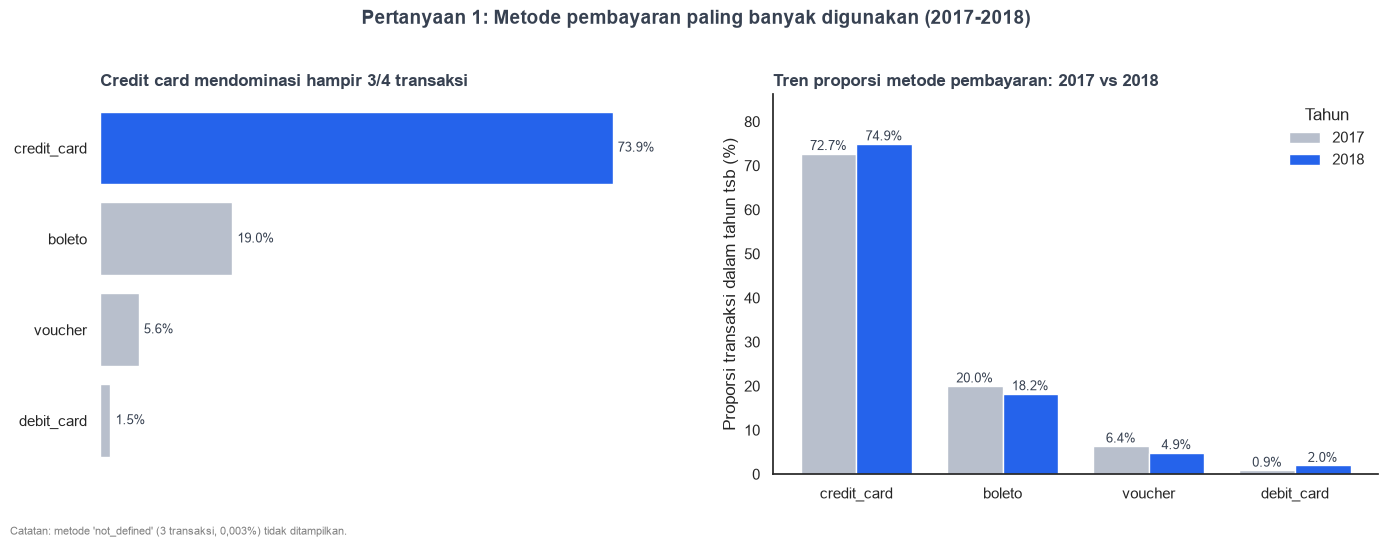

In [54]:
metode_pct = data_analisis_metode_pembayaran["payment_type"].value_counts(normalize=True) * 100
metode_pct = metode_pct.drop("not_defined", errors="ignore")   # 0,003% -> tidak ditampilkan

per_tahun = data_analisis_metode_pembayaran.groupby(["year", "payment_type"]).size().unstack(fill_value=0)
per_tahun_pct = per_tahun.div(per_tahun.sum(axis=1), axis=0) * 100
per_tahun_pct = per_tahun_pct.drop(columns="not_defined", errors="ignore")
urutan = metode_pct.sort_values(ascending=False).index
per_tahun_pct = per_tahun_pct[urutan]

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

barh_sorot(axes[0], metode_pct, ["credit_card"],
           "Credit card mendominasi hampir 3/4 transaksi",
           "Proporsi transaksi (%)", lambda v: f"{v:.1f}%")

x = np.arange(len(urutan)); lebar = 0.38
b17 = axes[1].bar(x - lebar / 2, per_tahun_pct.loc[2017], lebar, label="2017", color=WARNA_LAIN)
b18 = axes[1].bar(x + lebar / 2, per_tahun_pct.loc[2018], lebar, label="2018", color=WARNA_SOROT)
for barset in (b17, b18):
    for b in barset:
        axes[1].text(b.get_x() + b.get_width() / 2, b.get_height() + 0.8, f"{b.get_height():.1f}%",
                     ha="center", fontsize=9, color=WARNA_TEKS)
axes[1].set_xticks(x)
axes[1].set_xticklabels(urutan)
axes[1].set_ylim(0, per_tahun_pct.values.max() * 1.15)
axes[1].set_ylabel("Proporsi transaksi dalam tahun tsb (%)")
axes[1].set_title("Tren proporsi metode pembayaran: 2017 vs 2018", fontsize=12,
                  fontweight="bold", loc="left", color=WARNA_TEKS)
axes[1].legend(title="Tahun", frameon=False)
sn.despine(ax=axes[1])

fig.suptitle("Pertanyaan 1: Metode pembayaran paling banyak digunakan (2017-2018)",
             fontsize=14, fontweight="bold", color=WARNA_TEKS, y=1.02)
fig.text(0.01, -0.03, "Catatan: metode 'not_defined' (3 transaksi, 0,003%) tidak ditampilkan.",
         fontsize=8, color="gray")
plt.tight_layout()
plt.show()

**Insight:** (Opsional)
- selama periode 1 Januari 2017 hingga 17 Oktober 2018, `credit_card` adalah metode pembayaran yang paling banyak 
  digunakan, dengan kontribusi 73.9% dari seluruh transaksi. Jaraknya sangat jauh 
  dari `boleto` (19.0%), `voucher` (5.6%), dan `debit_card` (1.5%).
- Dominasi `credit_card` konsisten dari tahun ke tahun dan sedikit menguat, 
  dari 72.7% pada 2017 menjadi 74.9% pada 2018.
- Pergeseran preferensi antar metode pembayaran tergolong kecil. 
  Perubahan terbesar terjadi pada `credit_card`  sebesar 2,2 poin persentase (72.7% ke 74.9%), diikuti `boleto` yang turun 1,8 poin (20.0% ke 18.2%) dan `voucher` yang turun 1,5 poin (6.4% ke 4.9%).
- `debit_card` mengalami pertumbuhan porsi paling menonjol, dari 0.9% menjadi 
  2.0% (lebih dari 2 kali lipat). Namun porsinya masih sangat kecil, sehingga 
  belum bisa disimpulkan sebagai tren yang kuat dan perlu dipantau pada periode 
  berikutnya.
- Grafik tren menggunakan proporsi (%), bukan jumlah mentah, karena total 
  transaksi 2018 lebih besar dari 2017. Dengan proporsi, perubahan preferensi 
  bisa dibandingkan secara adil antar tahun.

### Pertanyaan 2: Kategori produk apa yang paling laris dibeli pelanggan selama 1 Januari hingga 3 September 2018, dan kategori apa yang berpotensi untuk ditambah stok/promosinya?

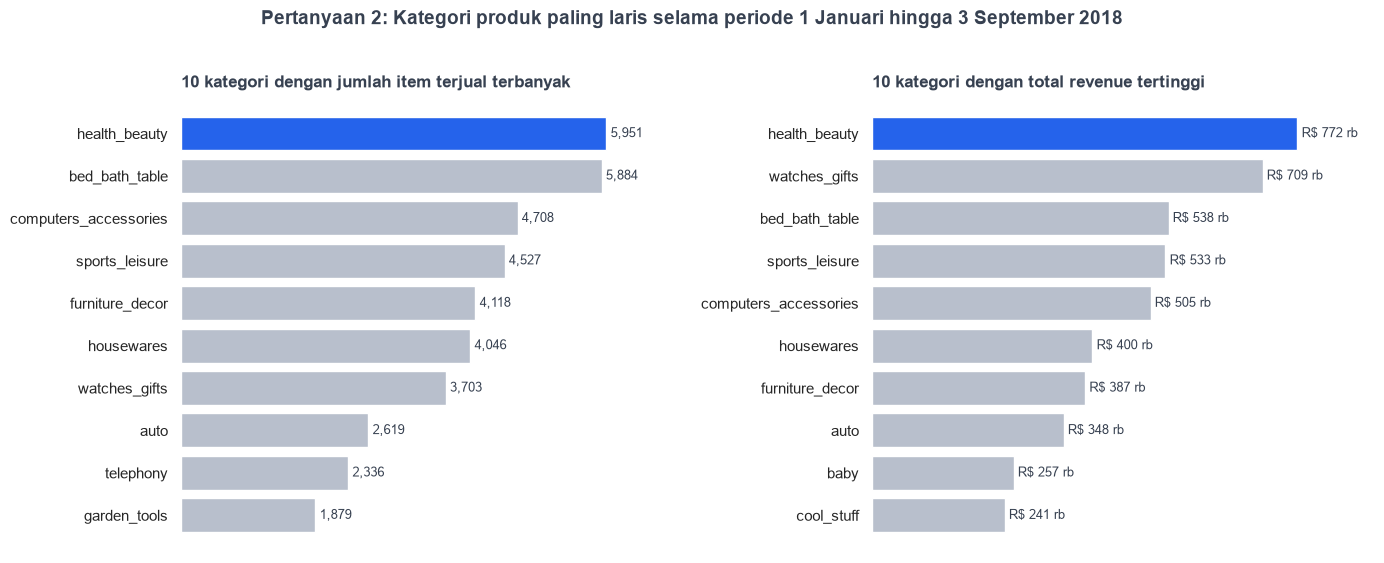

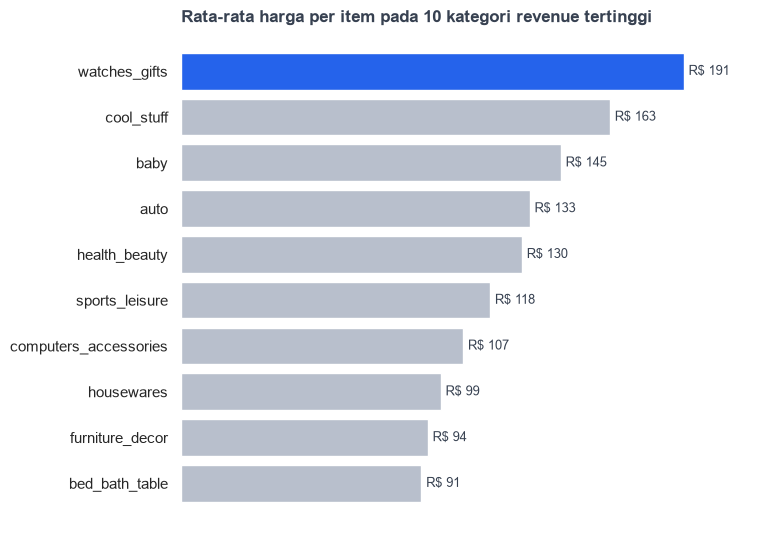

In [55]:
top_jumlah = data_analisis_kategori_produk["product_category_name_english"].value_counts().head(10)
top_revenue = (data_analisis_kategori_produk.groupby("product_category_name_english")["price"]
               .sum().sort_values(ascending=False).head(10))
rata_harga = (data_analisis_kategori_produk.groupby("product_category_name_english")["price"]
              .mean().loc[top_revenue.index])

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
barh_sorot(axes[0], top_jumlah, [top_jumlah.idxmax()],
           "10 kategori dengan jumlah item terjual terbanyak",
           "Jumlah item terjual", lambda v: f"{v:,.0f}")
barh_sorot(axes[1], top_revenue, [top_revenue.idxmax()],
           "10 kategori dengan total revenue tertinggi",
           "Total revenue (R$)", lambda v: f"R$ {v/1000:,.0f} rb")
fig.suptitle("Pertanyaan 2: Kategori produk paling laris selama periode 1 Januari hingga 3 September 2018",
             fontsize=14, fontweight="bold", color=WARNA_TEKS, y=1.02)
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(8, 5.5))
barh_sorot(ax, rata_harga, [rata_harga.idxmax()],
           "Rata-rata harga per item pada 10 kategori revenue tertinggi",
           "Rata-rata harga (R$)", lambda v: f"R$ {v:,.0f}")
plt.tight_layout()
plt.show()

**Insight:** (Opsional)
- Selama periode 1 Januari hingga 3 September 2018, `health_beauty` 
  menjadi kategori dengan jumlah item     terjual 
  terbanyak (5.951), disusul `bed_bath_table` (5.884). Selisih keduanya hanya 
  67 item (sekitar 1%), sehingga persaingannya sangat ketat. Keduanya unggul 
  jauh dari kategori ketiga, `computers_accessories` (4.708).
- `health_beauty` juga menempati peringkat pertama dari sisi total revenue 
  (R$ 772 rb), sehingga menjadi kategori dengan performa paling seimbang 
  antara volume dan nilai penjualan.
- `bed_bath_table` unggul di volume tetapi turun ke peringkat ketiga di revenue 
  (R$ 538 rb). Penyebabnya adalah rata-rata harga per itemnya paling rendah di 
  antara 10 kategori revenue tertinggi (R$ 91).
- `watches_gifts` hanya berada di peringkat ketujuh dari sisi volume (3.703 item), 
  tetapi menempati peringkat kedua dari sisi revenue (R$ 709 rb). Revenue-nya 
  hanya sekitar 8% di bawah `health_beauty` meskipun item terjualnya sekitar 
  38% lebih sedikit. Penyebabnya adalah rata-rata harganya tertinggi (R$ 191), 
  hampir dua kali lipat `health_beauty` (R$ 130).
- Artinya, "paling laris" bisa dibaca dari dua sisi. Kategori dengan volume 
  tinggi belum tentu paling menguntungkan, dan kategori dengan harga tinggi 
  bisa menyumbang revenue besar dengan volume lebih kecil.

## Analisis Lanjutan (Opsional)

### Analisis Lanjutan: Binning Jumlah Cicilan Kartu Kredit

**Tujuan:** Karena `credit_card` mendominasi metode pembayaran, analisis ini 
mengelompokkan (binning) transaksi kartu kredit berdasarkan jumlah cicilan selama periode 1 Januari 2017 hingga 17 Oktober 2018 
untuk mengetahui pola pembayaran pelanggan: apakah lebih banyak dibayar lunas 
atau dicicil, serta kelompok cicilan mana yang menyumbang nilai transaksi terbesar.

**Kelompok (manual grouping berdasarkan aturan bisnis):**
- Lunas (1x)
- Cicilan pendek (2-6x)
- Cicilan menengah (7-12x)
- Cicilan panjang (>12x)

In [56]:
kartu_kredit_df = data_analisis_metode_pembayaran[data_analisis_metode_pembayaran['payment_type'] == 'credit_card'].copy()

kartu_kredit_df['kelompok_cicilan'] = pd.cut(
    kartu_kredit_df['payment_installments'],
    bins=[0, 1, 6, 12, np.inf],
    labels=['Lunas (1x)', 'Cicilan pendek (2-6x)', 'Cicilan menengah (7-12x)', 'Cicilan panjang (>12x)']
)

ringkasan_cicilan = kartu_kredit_df.groupby('kelompok_cicilan', observed=True).agg(
    jumlah_transaksi=('payment_value', 'size'),
    rata_rata_nilai=('payment_value', 'mean'),
    total_nilai=('payment_value', 'sum')
)
ringkasan_cicilan['persen_transaksi'] = ringkasan_cicilan['jumlah_transaksi'] / ringkasan_cicilan['jumlah_transaksi'].sum() * 100
ringkasan_cicilan.round(1)

,jumlah_transaksi,rata_rata_nilai,total_nilai,persen_transaksi
kelompok_cicilan,,,,
Lunas (1x),25399,95.9,2435577.3,33.2
Cicilan pendek (2-6x),38992,153.8,5996703.6,50.9
Cicilan menengah (7-12x),11961,333.1,3984701.8,15.6
Cicilan panjang (>12x),185,413.7,76538.9,0.2


**Catatan**
  
jumlah_transaksi pada tabel ringkasan ini menghitung jumlah
catatan pembayaran kartu kredit, bukan jumlah pesanan unik. Satu
pesanan dapat memiliki lebih dari satu catatan pembayaran.

**Insight:** (Opsional)
- Transaksi kartu kredit paling banyak dibayar dengan cicilan pendek (2-6x), 
  yaitu 38.992 transaksi atau 50.9% dari seluruh transaksi kartu kredit. 
  Hanya 33.2% (25.399 transaksi) yang dibayar lunas (1x).
- Terdapat pola yang jelas: semakin panjang jangka cicilan, semakin besar 
  rata-rata nilai transaksinya — R$ 95,9 (lunas) → R$ 153,8 (2-6x) → 
  R$ 333,1 (7-12x) → R$ 413,7 (>12x). Ini mengindikasikan pelanggan 
  cenderung memilih cicilan untuk pembelian bernilai besar.
- Meskipun cicilan menengah (7-12x) hanya menyumbang 15.6% dari jumlah 
  transaksi, kontribusinya terhadap total nilai transaksi mencapai 
  R$ 3.984.701,8 atau sekitar 31% dari total nilai seluruh transaksi 
  kartu kredit — jauh lebih besar dari proporsi jumlah transaksinya.
- Cicilan panjang (>12x) sangat jarang digunakan (hanya 0.2% transaksi), 
  namun memiliki rata-rata nilai tertinggi (R$ 413,7), menunjukkan 
  kelompok ini biasa dipakai untuk pembelian bernilai sangat besar meski 
  jumlah penggunanya sedikit.

### Analisis Lanjutan: Segmentasi Kategori Produk (Manual Grouping)

**Tujuan:** Mengelompokkan 10 kategori dengan revenue tertinggi selama periode 1 Januari hingga 3 September 2018 ke dalam 
4 segmen berdasarkan jumlah item terjual dan rata-rata harga, dengan median 
kedua metrik sebagai batas. Segmentasi ini membantu menentukan kategori mana 
yang perlu diprioritaskan stoknya dan kategori mana yang perlu didorong lewat promosi.

In [57]:
agg_kategori = data_analisis_kategori_produk.groupby('product_category_name_english').agg(
    jumlah=('price', 'size'),
    rata_harga=('price', 'mean'),
    revenue=('price', 'sum')
)
top10 = agg_kategori.sort_values('revenue', ascending=False).head(10).copy()

median_jumlah = top10['jumlah'].median()
median_harga = top10['rata_harga'].median()

def tentukan_segmen(r):
    if r['jumlah'] >= median_jumlah and r['rata_harga'] >= median_harga:
        return 'Bintang (volume & harga tinggi)'
    elif r['jumlah'] >= median_jumlah:
        return 'Volume tinggi, harga rendah'
    elif r['rata_harga'] >= median_harga:
        return 'Premium, volume rendah'
    return 'Potensi rendah'

top10['segmen'] = top10.apply(tentukan_segmen, axis=1)
top10.sort_values(['segmen', 'revenue'], ascending=[True, False]).round(1)

,jumlah,rata_harga,revenue,segmen
product_category_name_english,,,,
health_beauty,5951,129.8,772238.2,Bintang (volume & harga tinggi)
housewares,4046,98.8,399888.1,Potensi rendah
watches_gifts,3703,191.4,708850.9,"Premium, volume rendah"
auto,2619,132.7,347631.2,"Premium, volume rendah"
baby,1776,144.6,256800.7,"Premium, volume rendah"
cool_stuff,1473,163.3,240559.2,"Premium, volume rendah"
bed_bath_table,5884,91.4,538069.3,"Volume tinggi, harga rendah"
sports_leisure,4527,117.6,532566.5,"Volume tinggi, harga rendah"
computers_accessories,4708,107.4,505476.3,"Volume tinggi, harga rendah"


**Catatan** 
 
`jumlah` menunjukkan jumlah item/baris produk yang tercatat
pada kategori, sedangkan `revenue` merupakan penjumlahan kolom price
atau total nilai penjualan produk. Nilai ini bukan keuntungan/laba dan
tidak mencakup biaya operasional. Nama variabel dipertahankan sesuai
kode notebook.

**Insight:** (Opsional)
- **Bintang (volume & harga tinggi):** Hanya `health_beauty` yang masuk 
  segmen ini, dengan 5.951 item terjual dan rata-rata harga R$ 129,8, 
  menghasilkan revenue tertinggi (R$ 772.238,2) di antara seluruh kategori 
  — sekitar 16.5% dari total revenue 10 kategori teratas.
- **Volume tinggi, harga rendah:** Diisi oleh `bed_bath_table`, 
  `sports_leisure`, `computers_accessories`, dan `furniture_decor`. 
  Keempatnya bersama-sama menyumbang 19.237 item terjual (volume terbesar 
  dari seluruh segmen) namun rata-rata harganya berkisar R$ 91,4-117,6 
  (paling rendah dari segmen lain), menghasilkan total revenue 
  R$ 1.962.780,7 atau sekitar 41.9% dari total — segmen dengan kontribusi 
  revenue terbesar justru datang dari volume, bukan harga.
- **Premium, volume rendah:** Diisi oleh `watches_gifts`, `auto`, `baby`, 
  dan `cool_stuff`. Volume totalnya hanya 9.571 item (hampir separuh dari 
  segmen volume tinggi), tetapi rata-rata harganya jauh lebih tinggi 
  (R$ 132,7-191,4), sehingga tetap menghasilkan revenue signifikan sebesar 
  R$ 1.553.842,0 (33.1% dari total) — hampir menyamai segmen volume tinggi 
  meski jumlah itemnya jauh lebih sedikit. `watches_gifts` menjadi yang 
  paling menonjol di segmen ini dengan rata-rata harga tertinggi 
  (R$ 191,4) dan revenue terbesar kedua secara keseluruhan.
- **Potensi rendah:** Hanya `housewares` yang masuk kategori ini, dengan 
  volume dan harga keduanya di bawah median, menyumbang revenue paling 
  kecil (R$ 399.888,1 atau 8.5% dari total).

## Conclusion & Recommendation

- **Conclusion pertanyaan 1:**  
Metode pembayaran `credit_card` merupakan metode yang paling banyak digunakan 
pelanggan selama periode 1 Januari 2017 hingga 17 Oktober 2018, dengan kontribusi 73.9% dari seluruh transaksi, 
jauh di atas `boleto` (19.0%), `voucher` (5.6%), dan `debit_card` (1.5%). 
Dominasi ini konsisten dari tahun ke tahun dan bahkan sedikit menguat, dari 
72.7% (2017) menjadi 74.9% (2018). Tidak ditemukan pergeseran preferensi yang 
signifikan antar metode pembayaran, kecuali pertumbuhan relatif pada 
`debit_card` yang naik lebih dari 2 kali lipat (0.9% → 2.0%), meski porsinya 
masih kecil secara keseluruhan. Analisis lanjutan juga menunjukkan bahwa 
mayoritas transaksi kartu kredit (66.8%) dibayar dengan cicilan, bukan lunas, 
dan semakin panjang jangka cicilan, semakin besar nilai transaksinya. 

- **Conclusion pertanyaan 2:**  
Kategori `health_beauty` merupakan kategori paling laris selama periode 1 Januari hingga 3 September 2018, baik 
dari sisi jumlah pesanan (5.951, tertinggi) maupun total revenue (R$ 772.238,2, 
tertinggi), menjadikannya satu-satunya kategori dengan performa seimbang 
(segmen "Bintang"). Kategori `bed_bath_table` bersaing sangat ketat dari sisi 
volume (5.884 pesanan, selisih hanya 1.1% dari `health_beauty`) namun kalah 
jauh dari sisi revenue akibat rata-rata harga yang lebih rendah (R$ 91,4 
dibanding R$ 129,8). Sementara itu, `watches_gifts` menonjol sebagai kategori 
premium — meski volume penjualannya hanya peringkat ke-7, rata-rata harganya 
tertinggi (R$ 191,4) sehingga tetap menghasilkan revenue terbesar kedua.

**Rekomendasi Action Item:**
- Pertahankan dan perkuat kemitraan dengan penyedia layanan kartu kredit, 
  karena metode ini menjadi tulang punggung revenue (menyumbang >75% dari 
  total nilai transaksi metode pembayaran) dan terus menguat dari tahun 
  ke tahun.
- Pantau pertumbuhan penggunaan `debit_card` sebagai sinyal awal pergeseran 
  preferensi pelanggan, dan pertimbangkan promosi tambahan pada metode ini 
  untuk mempercepat adopsinya.
- Tawarkan opsi cicilan menengah (7-12x) lebih menonjol pada proses checkout, 
  khususnya untuk produk bernilai tinggi, karena kelompok ini menyumbang 
  sekitar 31% dari total nilai transaksi kartu kredit meski hanya 15.6% 
  dari jumlah transaksinya.
- Prioritaskan ketersediaan stok pada kategori segmen "Bintang" dan "Volume 
  tinggi, harga rendah" (`health_beauty`, `bed_bath_table`, `sports_leisure`, 
  `computers_accessories`, `furniture_decor`), karena kelima kategori ini 
  menyumbang volume permintaan terbesar dan berisiko kehilangan penjualan 
  jika stok habis.
- Alokasikan anggaran promosi/marketing tambahan pada kategori segmen 
  "Premium, volume rendah" (`watches_gifts`, `auto`, `baby`, `cool_stuff`), 
  terutama `watches_gifts`, karena rata-rata nilai transaksinya tinggi namun 
  volume penjualannya masih dapat ditingkatkan — peningkatan volume sekecil 
  apapun pada kategori ini berdampak besar terhadap total revenue.